# RA3 — Parte 2: Visualizações e interpretação

Este notebook reúne os gráficos das perguntas P1 a P6, originalmente produzidos no notebook do RA1 (`HorrorMovieAnalysis.ipynb`), agora com título, nome dos eixos, unidades e legenda conferidos. Cada gráfico vem acompanhado de uma interpretação curta.

Os cálculos são os mesmos do RA1, feitos sobre a base limpa `horror_movies_limpo.csv`.

## Preparação do ambiente

In [1]:
# Bibliotecas para manipulação e visualização dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis durante a aula
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


## Carregamento da base limpa

A base é lida informando os tipos de cada coluna, do mesmo jeito que no fim do RA1, para que os valores ausentes continuem vazios e não virem zero. O arquivo local tem prioridade; se ele não existir (por exemplo, no Colab), a base é baixada do GitHub em uma versão fixa.

In [2]:
from pathlib import Path

tipos_csv = {
    "collection": "Int64", "budget": "Int64", "revenue": "Int64", "runtime": "Int64",
    "idioma": "string", "formato": "string", "nota_confiavel": "boolean",
    "ingles": "boolean", "franquia": "boolean",
}
arquivo_local = Path("horror_movies_limpo.csv")
url_csv = (
    "https://raw.githubusercontent.com/carlaferraz/HorrorMoviesData/"
    "e0bfb2b41182d7612323195c60c21818ce5df6a3/"
    "horror_movies_limpo.csv"
)
fonte_csv = arquivo_local if arquivo_local.exists() else url_csv

df = pd.read_csv(
    fonte_csv,
    parse_dates=["release_date"],
    dtype=tipos_csv,
)

print(f"Linhas: {df.shape[0]:,} | Colunas: {df.shape[1]}")

Linhas: 32,404 | Colunas: 25


## Regras usadas em todos os gráficos

- **Nota:** só entram filmes com `nota_confiavel` (10 votos ou mais).
- **Orçamento, receita e retorno:** só entram filmes com o valor informado.
- **Mediana em vez de média** quando a distribuição é muito assimétrica (popularidade, receita e retorno).

In [3]:
COR_PRINCIPAL = "#2a78d6"
COR_DESTAQUE = "#eb6834"
COR_NEUTRA = "#b5b3ad"

com_nota = df[df["nota_confiavel"]]
print(f"Filmes na base limpa: {len(df):,}")
print(f"Com nota confiável: {len(com_nota):,}")
print(f"Com orçamento informado: {int(df['budget'].notna().sum()):,}")
print(f"Com retorno calculado (orçamento e receita): {int(df['retorno'].notna().sum()):,}")

Filmes na base limpa: 32,404
Com nota confiável: 8,477
Com orçamento informado: 4,215
Com retorno calculado (orçamento e receita): 1,010


## P1 — Lançamentos por década e participação de outros idiomas

Pergunta: como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?

,filmes,nao_ingles,% não inglês
década,,,
1950s,340,136,40.0%
1960s,769,385,50.1%
1970s,"1,626",734,45.1%
1980s,"2,563","1,103",43.0%
1990s,"2,558",991,38.7%
2000s,"5,670","1,728",30.5%
2010s,"13,387","3,973",29.7%
2020s,"5,491","1,521",27.7%


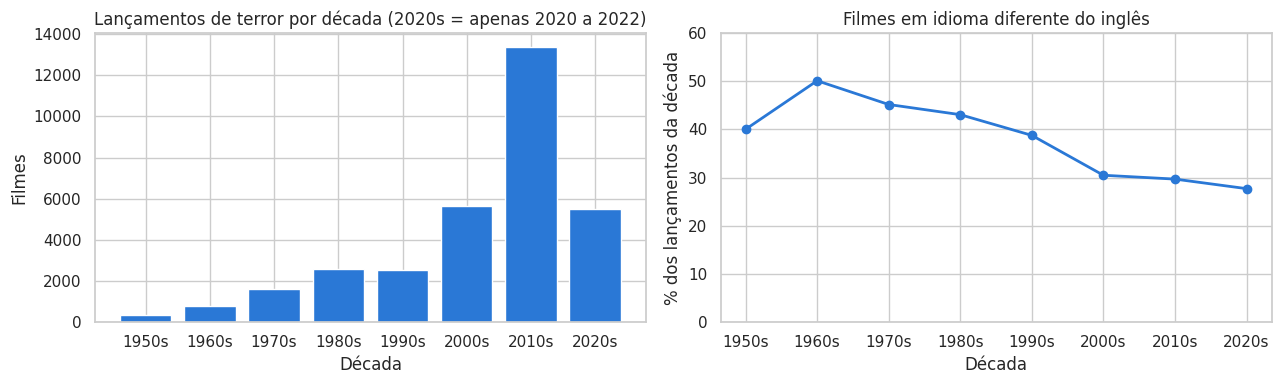

In [4]:
por_decada = df.groupby("decada").agg(
    filmes=("id", "size"),
    nao_ingles=("ingles", lambda serie: int((~serie).sum())),
)
por_decada["% não inglês"] = por_decada["nao_ingles"] / por_decada["filmes"] * 100
por_decada.index = [f"{decada}s" for decada in por_decada.index]
por_decada.index.name = "década"
display(por_decada.style.format({"filmes": "{:,}", "nao_ingles": "{:,}", "% não inglês": "{:.1f}%"}))

fig, (eixo_filmes, eixo_idioma) = plt.subplots(1, 2, figsize=(13, 4))
eixo_filmes.bar(por_decada.index, por_decada["filmes"], color=COR_PRINCIPAL)
eixo_filmes.set_title("Lançamentos de terror por década (2020s = apenas 2020 a 2022)")
eixo_filmes.set_ylabel("Filmes")
eixo_filmes.set_xlabel("Década")

eixo_idioma.plot(por_decada.index, por_decada["% não inglês"], color=COR_PRINCIPAL, linewidth=2, marker="o")
eixo_idioma.set_title("Filmes em idioma diferente do inglês")
eixo_idioma.set_xlabel("Década")
eixo_idioma.set_ylabel("% dos lançamentos da década")
eixo_idioma.set_ylim(0, 60)
plt.tight_layout()
plt.show()

**Interpretação:** o número de lançamentos cresceu fortemente a partir dos anos 2000: só a década de 2010 tem 13.387 filmes (41% da base), e 2020–2022 já se aproxima da década de 2000 inteira. A participação de filmes em idioma diferente do inglês caiu de 50,1% nos anos 1960 para 27,7% em 2020–2022.

## P2 — Orçamento e avaliação

Pergunta: filmes de terror com maior orçamento recebem avaliações médias maiores do público?

O orçamento é dividido em quatro faixas com a mesma quantidade aproximada de filmes (quartis).

Filmes analisados: 2,122
Correlação de Spearman entre orçamento e nota: 0.31


,filmes,orcamento_min,orcamento_max,nota_media,nota_mediana
faixa de orçamento,,,,,
1 - mais baixo,584,"US$ 1,000","US$ 500,000",5.07,5.0
2,480,"US$ 520,000","US$ 2,300,000",5.29,5.3
3,528,"US$ 2,393,600","US$ 8,000,000",5.60,5.7
4 - mais alto,530,"US$ 8,300,000","US$ 200,000,000",5.96,6.0


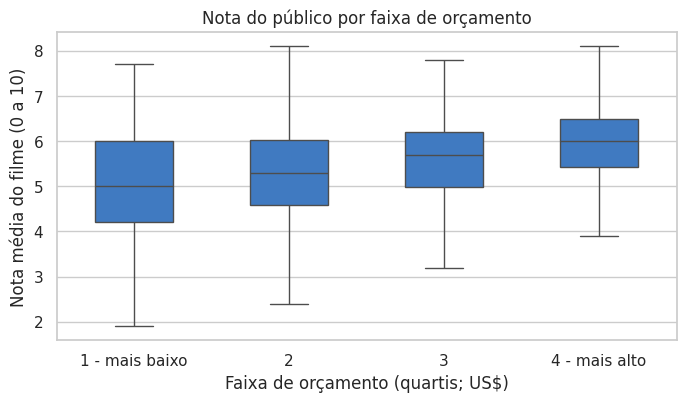

In [5]:
base_p2 = com_nota[com_nota["budget"].notna()].copy()
orcamento = base_p2["budget"].astype(float)
correlacao = orcamento.rank().corr(base_p2["vote_average"].rank())

FAIXAS = ["1 - mais baixo", "2", "3", "4 - mais alto"]
base_p2["faixa de orçamento"] = pd.qcut(orcamento, 4, labels=FAIXAS)
p2 = base_p2.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    nota_media=("vote_average", "mean"),
    nota_mediana=("vote_average", "median"),
)

print(f"Filmes analisados: {len(base_p2):,}")
print(f"Correlação de Spearman entre orçamento e nota: {correlacao:.2f}")
display(p2.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "nota_media": "{:.2f}", "nota_mediana": "{:.1f}",
}))

plt.figure(figsize=(8, 4))
sns.boxplot(data=base_p2, x="faixa de orçamento", y="vote_average", color=COR_PRINCIPAL,
            showfliers=False, width=0.5)
plt.title("Nota do público por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis; US$)")
plt.ylabel("Nota média do filme (0 a 10)")
plt.show()

**Interpretação:** a nota média sobe a cada faixa, de 5,07 nos filmes mais baratos (até US$ 500 mil) para 5,96 nos mais caros (a partir de US$ 8,3 milhões), mas a correlação de Spearman é fraca (0,31) e as caixas se sobrepõem bastante. A comparação cobre 2.122 filmes com orçamento e nota confiável, cerca de 7% da base.

## P3 — Retorno proporcional por faixa de orçamento

Pergunta: entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita ÷ orçamento) maior que os de alto orçamento?

Retorno 2 significa que o filme faturou o dobro do que custou.

Filmes analisados: 1,010


,filmes,orcamento_min,orcamento_max,retorno_mediano,retorno_medio,pct_receita_maior
faixa de orçamento,,,,,,
1 - mais baixo,253,"US$ 1,000","US$ 1,800,000",3.08×,78.86×,70.8%
2,253,"US$ 1,900,000","US$ 6,500,000",2.00×,5.08×,63.2%
3,266,"US$ 6,600,000","US$ 17,000,000",2.13×,4.08×,68.4%
4 - mais alto,238,"US$ 18,000,000","US$ 200,000,000",2.03×,2.45×,73.5%


Maiores retornos da base:


title,ano,budget,revenue,retorno
One Cut of the Dead,2017,"US$ 30,000","US$ 200,000,000","6,667×"
The Blair Witch Project,1999,"US$ 60,000","US$ 248,639,099","4,144×"
Routs,2022,"US$ 25,000","US$ 50,000,000","2,000×"
Paranormal Activity,2007,"US$ 215,000","US$ 194,183,034",903×
Lady Frankenstein,1971,"US$ 200,000","US$ 139,683,000",698×


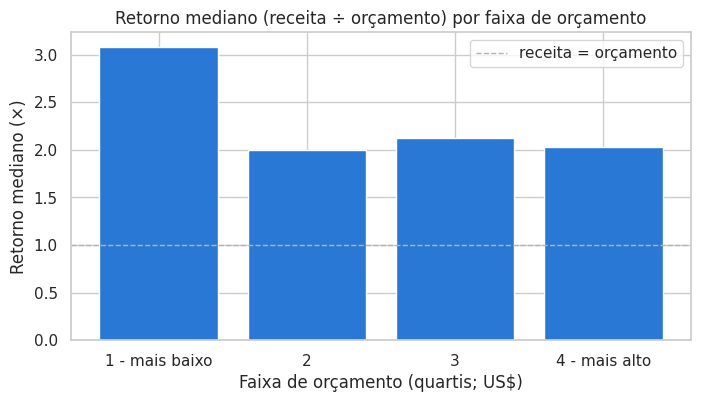

In [6]:
base_p3 = df[df["retorno"].notna()].copy()
base_p3["faixa de orçamento"] = pd.qcut(base_p3["budget"].astype(float), 4, labels=FAIXAS)
p3 = base_p3.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    retorno_mediano=("retorno", "median"),
    retorno_medio=("retorno", "mean"),
    pct_receita_maior=("retorno", lambda serie: (serie > 1).mean() * 100),
)

print(f"Filmes analisados: {len(base_p3):,}")
display(p3.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "retorno_mediano": "{:.2f}×", "retorno_medio": "{:.2f}×", "pct_receita_maior": "{:.1f}%",
}))

print("Maiores retornos da base:")
display(
    base_p3.nlargest(5, "retorno")[["title", "ano", "budget", "revenue", "retorno"]]
    .style.hide(axis="index")
    .format({"budget": "US$ {:,.0f}", "revenue": "US$ {:,.0f}", "retorno": "{:,.0f}×"})
)

plt.figure(figsize=(8, 4))
plt.bar(p3.index.astype(str), p3["retorno_mediano"], color=COR_PRINCIPAL)
plt.axhline(1, color=COR_NEUTRA, linestyle="--", linewidth=1, label="receita = orçamento")
plt.legend(loc="upper right")
plt.title("Retorno mediano (receita ÷ orçamento) por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis; US$)")
plt.ylabel("Retorno mediano (×)")
plt.show()

**Interpretação:** o retorno mediano da faixa mais barata (até US$ 1,8 milhão) é 3,1×, contra cerca de 2× nas outras três faixas. Já a proporção de filmes que faturam mais do que custaram é parecida entre as faixas (de 63% a 74%). A análise cobre os 1.010 filmes com orçamento e receita informados.

## P4 — Gêneros combinados ao terror

Pergunta: quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?

Cada filme é desmembrado em uma linha por gênero, e o próprio "Horror" é retirado. Entram os gêneros presentes em pelo menos 300 filmes.

Filmes classificados só como Horror: 12,422 (38.3%)


,filmes,% dos filmes,filmes_com_nota,nota_media,popularidade_mediana
genero,,,,,
Thriller,"7,640",23.6%,"3,293",5.42,1.63
Comedy,"4,940",15.2%,"1,190",5.49,0.88
Drama,"4,254",13.1%,"1,296",5.74,0.91
Mystery,"3,125",9.6%,"1,285",5.72,1.40
Science Fiction,"2,703",8.3%,"1,333",5.14,1.96
Fantasy,"2,188",6.8%,738,5.70,1.11
Action,"1,959",6.0%,826,5.22,1.65
Crime,"1,151",3.6%,426,5.65,1.40
Animation,972,3.0%,174,6.47,0.60


Combinações exatas mais comuns:


,filmes
genre_names,
Horror,12422
"Horror, Thriller",3241
"Comedy, Horror",2831
"Drama, Horror",1323
"Horror, Science Fiction",923
"Horror, Mystery, Thriller",859


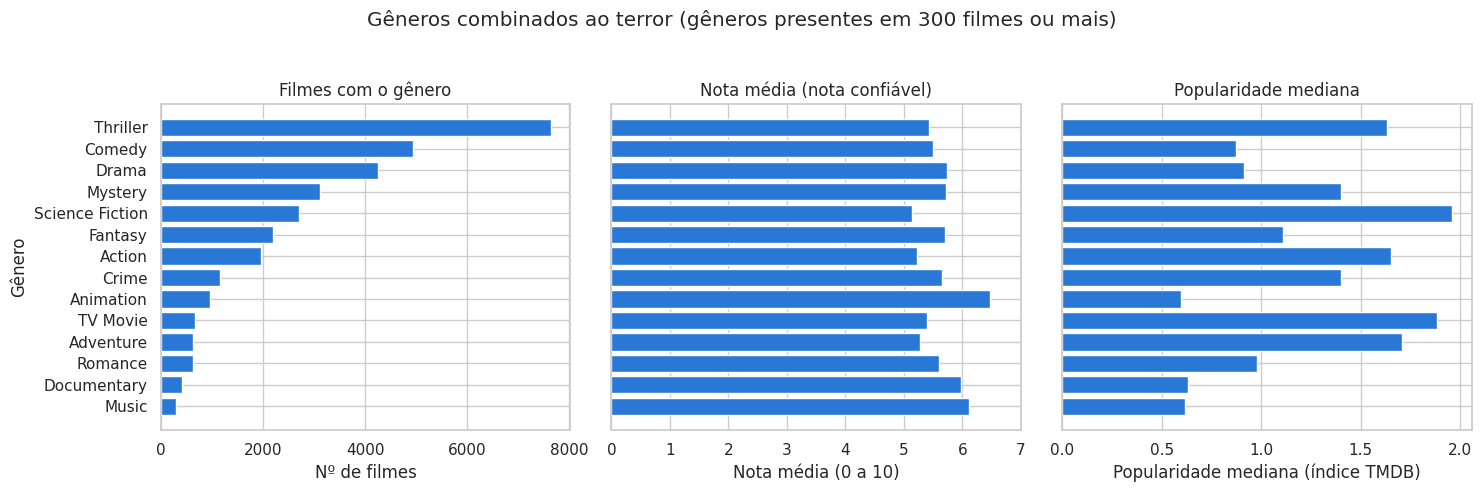

In [7]:
generos = (
    df.assign(genero=df["genre_names"].str.split(", "))
    .explode("genero")
    .query("genero != 'Horror'")
)
so_terror = int(df["genre_names"].eq("Horror").sum())
print(f"Filmes classificados só como Horror: {so_terror:,} ({so_terror / len(df):.1%})")

p4 = generos.groupby("genero").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
).join(
    generos[generos["nota_confiavel"]].groupby("genero").agg(
        filmes_com_nota=("id", "size"),
        nota_media=("vote_average", "mean"),
    )
)
p4["% dos filmes"] = p4["filmes"] / len(df) * 100
p4 = p4[p4["filmes"].ge(300)].sort_values("filmes", ascending=False)

display(p4[["filmes", "% dos filmes", "filmes_com_nota", "nota_media", "popularidade_mediana"]].style.format({
    "filmes": "{:,}", "% dos filmes": "{:.1f}%", "filmes_com_nota": "{:,}",
    "nota_media": "{:.2f}", "popularidade_mediana": "{:.2f}",
}))

print("Combinações exatas mais comuns:")
display(df["genre_names"].value_counts().head(6).rename("filmes").to_frame())

fig, eixos = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
ordem = p4.index[::-1]
for eixo, coluna, titulo in zip(
    eixos,
    ["filmes", "nota_media", "popularidade_mediana"],
    ["Filmes com o gênero", "Nota média (nota confiável)", "Popularidade mediana"],
):
    eixo.barh(ordem, p4.loc[ordem, coluna], color=COR_PRINCIPAL)
    eixo.set_title(titulo)
eixos[0].set_xlabel("Nº de filmes")
eixos[1].set_xlabel("Nota média (0 a 10)")
eixos[2].set_xlabel("Popularidade mediana (índice TMDB)")
eixos[0].set_ylabel("Gênero")
eixos[1].set_xlim(0, 7)
fig.suptitle("Gêneros combinados ao terror (gêneros presentes em 300 filmes ou mais)")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Interpretação:** os nomes dos gêneros estão em inglês, como na base. **Thriller** é o parceiro mais frequente (7.640 filmes, 23,6% da base), seguido de Comedy, Drama e Mystery, enquanto 38,3% dos filmes são classificados só como Horror. As maiores notas médias são de Animation (6,47), Music (6,12) e Documentary (5,97); as maiores popularidades medianas são de Science Fiction (1,96), TV Movie (1,88), Adventure e Action, que têm notas entre 5,14 e 5,39.

## P5 — Lançamentos em outubro

Pergunta: existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?

As datas de **1º de janeiro** ficam fora desta contagem: o TMDB grava essa data quando só o ano do lançamento é conhecido, o que inflaria janeiro.

Filmes com data em 1º de janeiro: 3,836 de 5,582 lançados em janeiro
Lançados exatamente em 31 de outubro: 503


,filmes,popularidade_mediana,popularidade_media,nota_media,filmes por mês
periodo,,,,,
outros meses,"23,798",0.88,4.50,5.37,"2,163"
outubro,"4,770",0.84,3.83,5.39,"4,770"


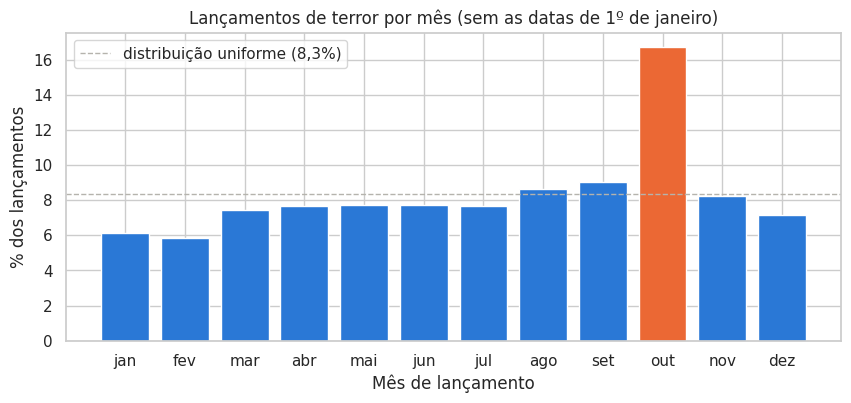

In [8]:
primeiro_janeiro = df["release_date"].dt.month.eq(1) & df["release_date"].dt.day.eq(1)
print(f"Filmes com data em 1º de janeiro: {int(primeiro_janeiro.sum()):,} "
      f"de {int(df['mes'].eq(1).sum()):,} lançados em janeiro")

base_p5 = df[~primeiro_janeiro].copy()
base_p5["periodo"] = np.where(base_p5["mes"].eq(10), "outubro", "outros meses")

nomes_meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
por_mes = base_p5["mes"].value_counts(normalize=True).sort_index().mul(100)
por_mes.index = nomes_meses

outubro_31 = int((base_p5["mes"].eq(10) & base_p5["release_date"].dt.day.eq(31)).sum())
print(f"Lançados exatamente em 31 de outubro: {outubro_31:,}")

p5 = base_p5.groupby("periodo").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
    popularidade_media=("popularity", "mean"),
).join(base_p5[base_p5["nota_confiavel"]].groupby("periodo").agg(nota_media=("vote_average", "mean")))
p5["filmes por mês"] = p5["filmes"] / np.where(p5.index == "outubro", 1, 11)
display(p5.style.format({
    "filmes": "{:,}", "filmes por mês": "{:,.0f}", "popularidade_mediana": "{:.2f}",
    "popularidade_media": "{:.2f}", "nota_media": "{:.2f}",
}))

plt.figure(figsize=(10, 4))
plt.bar(por_mes.index, por_mes.values,
        color=[COR_DESTAQUE if mes == "out" else COR_PRINCIPAL for mes in por_mes.index])
plt.axhline(100 / 12, color=COR_NEUTRA, linestyle="--", linewidth=1, label="distribuição uniforme (8,3%)")
plt.legend(loc="upper left")
plt.title("Lançamentos de terror por mês (sem as datas de 1º de janeiro)")
plt.xlabel("Mês de lançamento")
plt.ylabel("% dos lançamentos")
plt.show()

**Interpretação:** sem as 3.836 datas de 1º de janeiro, outubro concentra 16,7% dos lançamentos, o dobro da distribuição uniforme (8,3%) e quase o dobro do segundo colocado, setembro (9,0%). A popularidade mediana de outubro (0,84) é próxima à dos outros meses (0,88), assim como a nota média (5,39 contra 5,37).

## P6 — Filmes de franquia e filmes avulsos

Pergunta: filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

,filmes,filmes com nota,nota média,filmes com receita,receita mediana,retorno mediano,popularidade mediana
franquia,"2,302","1,447",5.50,467,"US$ 22,000,000",3.52×,3.80
avulso,"30,102","7,030",5.32,"1,016","US$ 2,064,798",1.22×,0.71


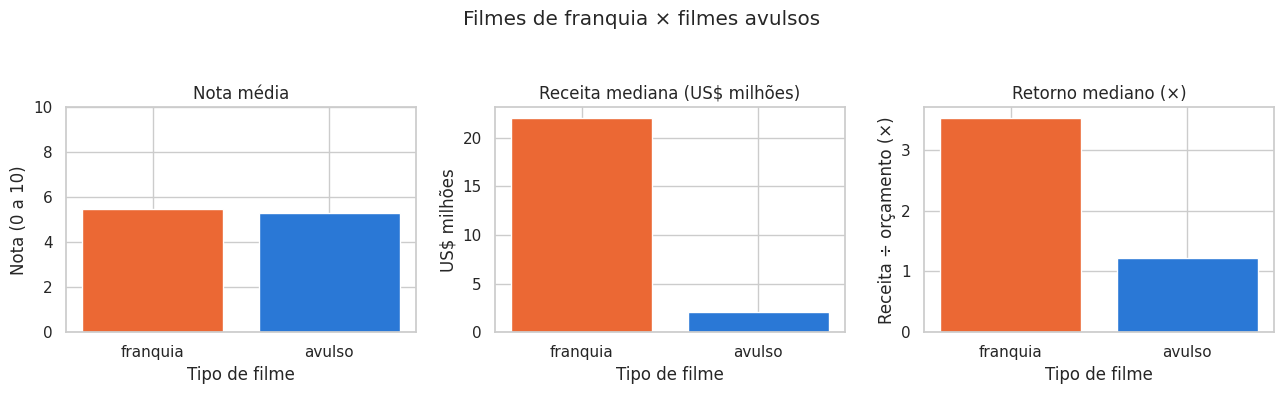

In [9]:
grupos = {True: "franquia", False: "avulso"}
p6 = pd.DataFrame({
    "filmes": df.groupby("franquia")["id"].size(),
    "filmes com nota": com_nota.groupby("franquia")["id"].size(),
    "nota média": com_nota.groupby("franquia")["vote_average"].mean(),
    "filmes com receita": df[df["revenue"].notna()].groupby("franquia")["id"].size(),
    "receita mediana": df.groupby("franquia")["revenue"].median(),
    "retorno mediano": df.groupby("franquia")["retorno"].median(),
    "popularidade mediana": df.groupby("franquia")["popularity"].median(),
}).rename(index=grupos).loc[["franquia", "avulso"]].rename_axis(None)

display(p6.style.format({
    "filmes": "{:,}", "filmes com nota": "{:,}", "nota média": "{:.2f}", "filmes com receita": "{:,}",
    "receita mediana": "US$ {:,.0f}", "retorno mediano": "{:.2f}×", "popularidade mediana": "{:.2f}",
}))

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
cores = [COR_DESTAQUE, COR_PRINCIPAL]
for eixo, coluna, titulo, escala in zip(
    eixos,
    ["nota média", "receita mediana", "retorno mediano"],
    ["Nota média", "Receita mediana (US$ milhões)", "Retorno mediano (×)"],
    [1, 1e6, 1],
):
    eixo.bar(p6.index, p6[coluna] / escala, color=cores)
    eixo.set_title(titulo)
    eixo.set_xlabel("Tipo de filme")
eixos[0].set_ylabel("Nota (0 a 10)")
eixos[1].set_ylabel("US$ milhões")
eixos[2].set_ylabel("Receita ÷ orçamento (×)")
eixos[0].set_ylim(0, 10)
fig.suptitle("Filmes de franquia × filmes avulsos")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Interpretação:** a nota média é próxima (5,50 para filmes de franquia contra 5,32 para avulsos), mas a receita mediana da franquia é cerca de dez vezes maior (US$ 22 milhões contra US$ 2,1 milhões) e o retorno mediano é 3,5× contra 1,2×. A popularidade mediana também é bem maior (3,80 contra 0,71).